In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures')

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

In [2]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

tstop = exp_dpl.times[-1]+100
scale_factor = 1000
smooth_window_len = 5

In [3]:
def net_block_dend_ca(net, cell_type='L5_pyramidal'):

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for sec in sections:
        net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = [0]*len(net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_HVA']['gbar_Ca_HVA'][1])
        net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = [0]*len(net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])

    return net

In [4]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_basket': 0.001, 
                   'L2_pyramidal': 0.075,
                   'L5_basket': 0.0, 
                   'L5ET': 0.001}
weights_nmda_p1 = {'L2_basket': 0.001, 'L2_pyramidal': 0.05,
                   'L5_basket': 0.0075, 'L5ET': .0}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5ET': 1.}

net.add_evoked_drive('prox1', mu=18, sigma=2.5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

weights_ampa_d1 = {'L2_basket': 0.005, 'L2_pyramidal': 0.01, 'L5ET': 1.}
weights_nmda_d1 = {'L2_basket': 0.0, 'L2_pyramidal': .01, 'L5ET': 1.}
synaptic_delays_dist = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,'L5ET': 0.1}

net.add_evoked_drive('dist1', mu=62, sigma=5, numspikes=2, weights_ampa=weights_ampa_d1,
    weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

weights_ampa_p2 = {'L2_basket': 0.05, 'L2_pyramidal': .1,
                   'L5_basket': 0.05, 'L5ET': 0.8}
weights_nmda_p2 = {'L2_basket': 0.001, 'L2_pyramidal': 0.05,
                   'L5_basket': 0.005, 'L5ET': .5}
synaptic_delays_prox = {'L2_basket': 0.01, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5ET': 1.}
net.add_evoked_drive('prox2', mu=100, sigma=10, numspikes=1, weights_ampa=weights_ampa_p2,
    weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)


with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='duecker')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading cu

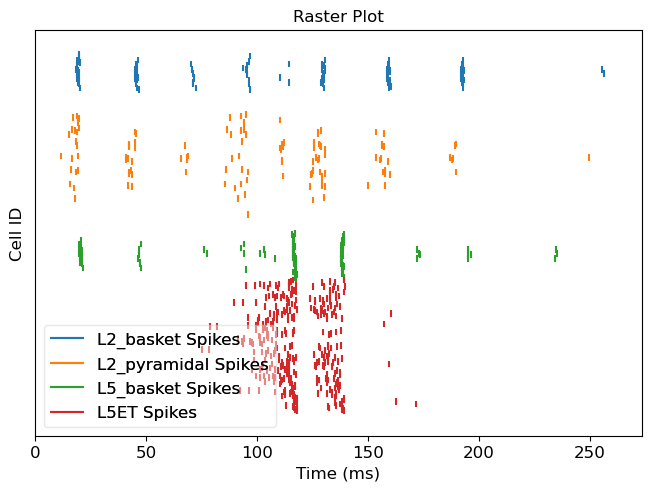

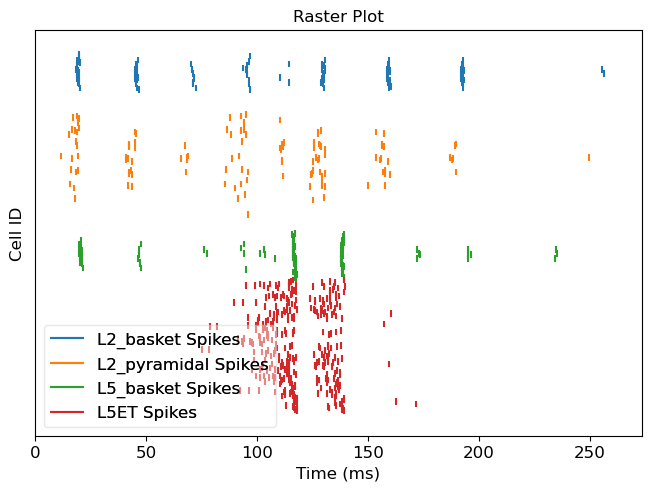

In [5]:
net.cell_response.plot_spikes_raster()

In [6]:
net.cell_response._cell_type_names

['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5ET']

In [7]:
dpl = [d.scale(scale_factor) for d in dpl]
dpl = [d.smooth(smooth_window_len) for d in dpl]


In [8]:
avg_dpl = average_dipoles(dpl)

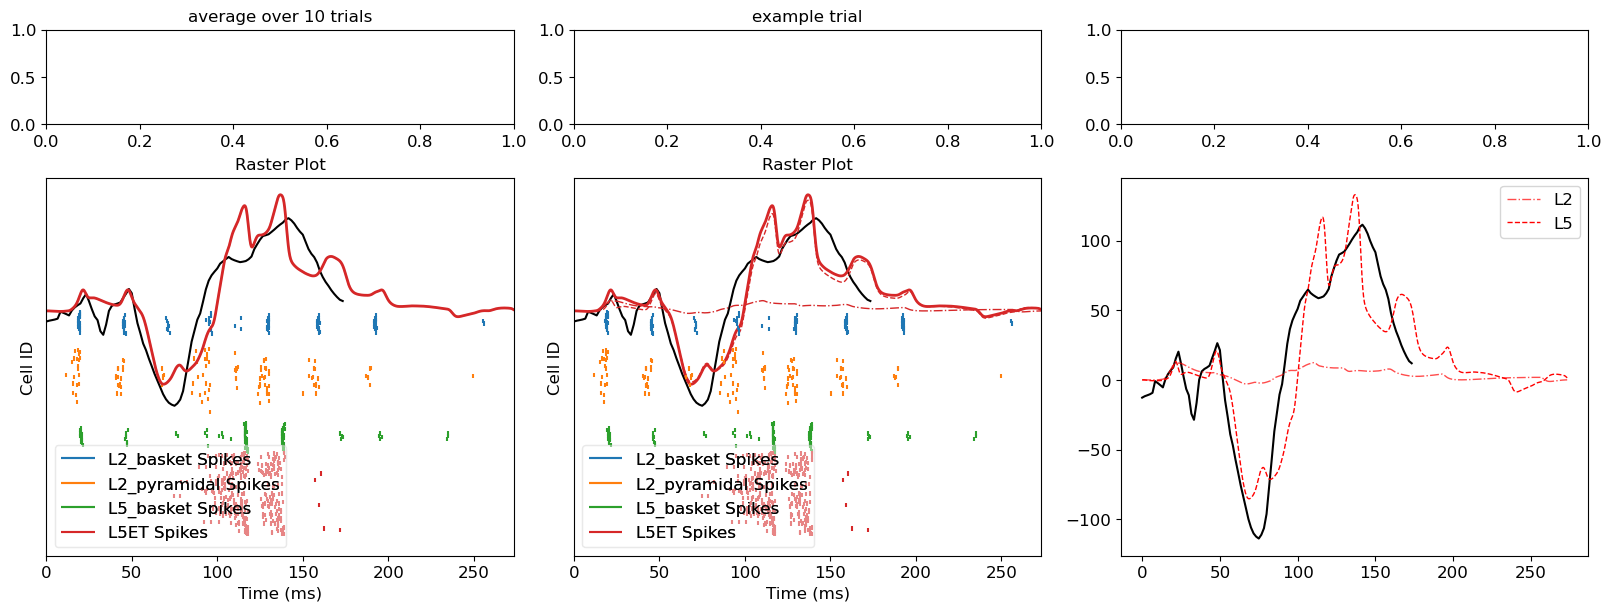

In [9]:
fig, ax = plt.subplots(2,3, figsize=(16,6), height_ratios=[0.25, 1], constrained_layout=True)

# for i in range(3):
#     net.cell_response.plot_spikes_hist(ax=ax[0,i], show=False, invert_spike_types='dist1')
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)
for d in dpl:
    ax[1,0].plot(d.times, d.data['agg'], color='gray', alpha=0.3)

ax[1,0].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,0].plot(avg_dpl.times, avg_dpl.data['agg'], linewidth=2, color='C3')

ax[1,1].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,1].plot(dpl[0].times, dpl[0].data['agg'], linewidth=2, color='C3', label='agg')
ax[1,1].plot(dpl[0].times, dpl[0].data['L5'], linewidth=1, color='C3', linestyle='--', label='L5')
ax[1,1].plot(dpl[0].times, dpl[0].data['L2'], linewidth=1, color='C3', linestyle='-.', label='L2')
ax[1,1].legend()

ax[0,0].set_title('average over 10 trials')
ax[0,1].set_title('example trial')

net.cell_response.plot_spikes_raster(ax=ax[1,1], trial_idx=0, show=False)

#net.cell_response.plot_spikes_hist(ax=ax[0,2], show=False, invert_spike_types='dist1')
ax[1,2].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,2].plot(dpl[0].times, dpl[0].data['L2'], linewidth=1, color='r', alpha=0.7, linestyle='-.', label='L2')
ax[1,2].plot(dpl[0].times, dpl[0].data['L5'], linewidth=1, color='r', label='L5', linestyle='--')
ax[1,2].legend()
fig.savefig(f'{pathfig}/handtuned_ERP.png')

In [10]:
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_dt = simulate_dipole(net, tstop=tstop, n_trials=5,dt=0.05, bsl_cor='duecker')

MPI will run 5 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:211: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


RuntimeError: MPI simulation failed. Return code: 1

In [2]:
dpl_dt = [d.scale(scale_factor) for d in dpl_dt]

NameError: name 'dpl_dt' is not defined

In [3]:
avg_dpl_dt = average_dipoles(dpl_dt)

plt.plot(avg_dpl_dt.times, avg_dpl_dt.data['agg'])
plt.plot(exp_dpl.times, exp_dpl.data['agg'], color='k')
plt.plot(avg_dpl.times, avg_dpl.data['agg'], color='r')

NameError: name 'average_dipoles' is not defined

In [4]:
_rmse_dt = _rmse(avg_dpl_dt, exp_dpl, tstop=tstop)
print(f'RMSE: {_rmse_dt} nAm')
_rmse_og = _rmse(avg_dpl, exp_dpl, tstop=tstop)
print(f'Original RMSE: {_rmse_og} nAm')

NameError: name '_rmse' is not defined

In [5]:
plt.plot(net.cell_response.isec[0][135]['soma']['soma_ampa'])
plt.plot(net.cell_response.isec[0][135]['soma']['soma_nmda'])

NameError: name 'plt' is not defined

In [ ]:
spike_gids = np.array(net.cell_response.spike_gids[0])
spike_gid_id = np.where((spike_gids >=170) & (spike_gids < 270))
l5_gids = spike_gids[spike_gid_id[0]]

In [ ]:
l5_gids

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(10,4), constrained_layout=True)
cell_id = l5_gids[1]
ax[0].plot(dpl[0].times, net.cell_response.vsec[0][cell_id]['soma'])
ax[0].plot(dpl[0].times, net.cell_response.vsec[0][cell_id]['apical_tuft'])
ax[1].plot(dpl[0].times, net.cell_response.isec[0][cell_id]['apical_tuft']['apical_tuft_ampa'])
ax[1].plot(dpl[0].times, net.cell_response.isec[0][cell_id]['apical_tuft']['apical_tuft_nmda'])

In [ ]:
from optimize_drives_slurm import set_params, set_params_time, rmse_evk_corr
with open(f'dpl_drives_1000_nmdamodel.pkl', 'rb') as file:
        dpl = pickle.load(file)

plt.plot(dpl.times, dpl.data['agg'])

In [ ]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_tuft']['apical_tuft_gabab'])



In [ ]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_2']['apical_2_gabaa'])


In [ ]:
plt.plot(np.abs(np.array(net.cell_response.ca[0][200]['basal_3'])-5e-5)/5e-5)

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(12,6), constrained_layout=True)
net.rec_arrays['probe1'][0].plot_lfp(ax=axs[0], show=False, voltage_offset=200)
net.rec_arrays['probe1'][0].plot_csd(ax=axs[1], show=False, sink='r')


In [ ]:
lfp = net.rec_arrays['probe1'][0].voltages

In [ ]:
from scipy import signal


sos = signal.butter(4, 300, 'lp', fs=dpl[0].sfreq, output='sos')
filtered = signal.sosfilt(sos, lfp)

In [ ]:
filtered

In [ ]:
plt.plot(net.cell_response.times, filtered[0,0])
plt.plot(net.cell_response.times, lfp[0,0])
